In [1]:
#!pip install tensorflow==2.7.0

In [2]:
#!pip install keras==2.7.0

In [3]:
#!pip install pydot

In [4]:
# Basic Libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import pydot
import seaborn as sns

#Evaluation library
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

# Deep Learning libraries
import tensorflow as tf
from tensorflow.keras import layers
import keras
from keras.models import Sequential
from keras.layers.core import Dense,Activation,Dropout
from keras.datasets import mnist
from keras.utils.np_utils import to_categorical
from keras.wrappers.scikit_learn import KerasClassifier

In [5]:
#Digit MNIST dataset
(X_train_digit,y_train_digit),(X_test_digit,y_test_digit) = mnist.load_data()

In [6]:
print(X_train_digit.shape)
print(y_train_digit.shape)
print(X_test_digit.shape)
print(y_test_digit.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [7]:
# Pixel represented in 0-256(greyscale)
X_train_digit[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [8]:
y_train_digit[0]

5

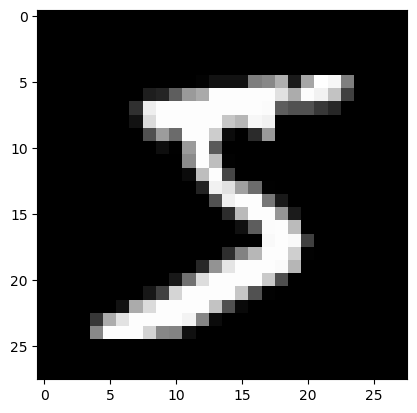

In [9]:
#actual first image
plt.imshow(X_train_digit[0], cmap='gray')
plt.show()

In [10]:
#actual first image label
print(y_train_digit[0])

5


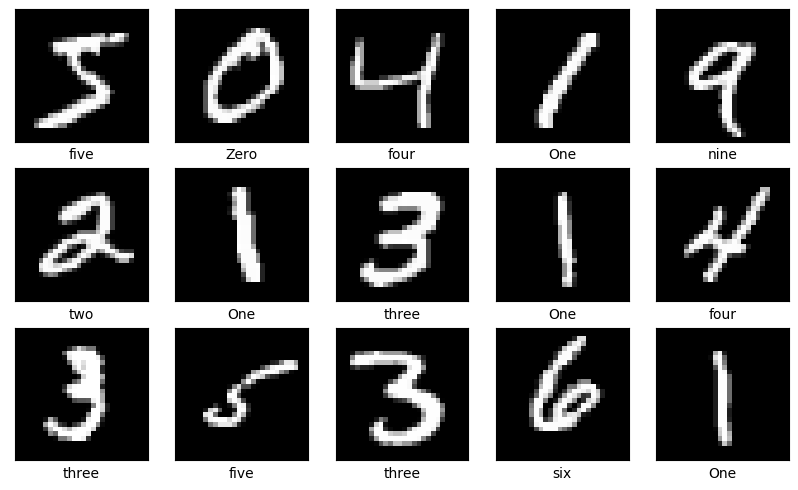

In [11]:
#Take the first 15 MNIST images and display them in a grid, with the correct digit name underneath each image
col_names = ['Zero','One','two','three','four','five','six','seven','eight','nine']

plt.figure(figsize=(10,10))

for i in range(15):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(X_train_digit[i], cmap='gray')
    plt.xlabel(col_names[y_train_digit[i]])
    
plt.show()

In [12]:
X_train_digit.shape

(60000, 28, 28)

In [13]:
#Flatten images - Dense layers in ANN needs as 1D
X_train_digit = X_train_digit.reshape(60000, 784)

X_test_digit = X_test_digit.reshape(10000, 784)

In [14]:
X_train_digit.shape

(60000, 784)

In [15]:
y_test_digit.shape

(10000,)

In [16]:
y_test_digit

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

In [17]:
#One hot encoding MNIST Labels
y_train_digit = to_categorical(y_train_digit,num_classes=10)

y_test_digit = to_categorical (y_test_digit,num_classes=10)

In [18]:
y_train_digit[1]

array([1., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [19]:
#Neural network
model = keras.Sequential([
    layers.Dense(256,activation='relu',input_shape=(784,)),
    layers.Dense(64,activation='relu'),
    layers.Dense(64,activation='relu'),
    layers.Dense(10,activation='sigmoid'),    
])

In [20]:
#Prepare for training the model
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=['accuracy']
)

In [21]:
#model training
history = model.fit(
        X_train_digit,
        y_train_digit,
        batch_size=100,
        epochs=10,
        validation_data=(X_test_digit,y_test_digit)
)

Epoch 1/10
600/600 [==============================] - 3s 4ms/step - loss: 1.6617 - accuracy: 0.8415 - val_loss: 0.4246 - val_accuracy: 0.8987
Epoch 2/10
600/600 [==============================] - 2s 3ms/step - loss: 0.2619 - accuracy: 0.9315 - val_loss: 0.2588 - val_accuracy: 0.9376
Epoch 3/10
600/600 [==============================] - 2s 3ms/step - loss: 0.1762 - accuracy: 0.9515 - val_loss: 0.2178 - val_accuracy: 0.9466
Epoch 4/10
600/600 [==============================] - 2s 3ms/step - loss: 0.1428 - accuracy: 0.9607 - val_loss: 0.2249 - val_accuracy: 0.9506
Epoch 5/10
600/600 [==============================] - 1s 2ms/step - loss: 0.1115 - accuracy: 0.9679 - val_loss: 0.2140 - val_accuracy: 0.9424
Epoch 6/10
600/600 [==============================] - 2s 3ms/step - loss: 0.1061 - accuracy: 0.9704 - val_loss: 0.1724 - val_accuracy: 0.9626
Epoch 7/10
600/600 [==============================] - 2s 4ms/step - loss: 0.0950 - accuracy: 0.9726 - val_loss: 0.1562 - val_accuracy: 0.9613
Epoch 

In [22]:
y_predict = model.predict(X_test_digit)

In [23]:
y_predict

array([[1.6596320e-07, 4.8825458e-01, 6.6949064e-01, ..., 1.0000000e+00,
        4.5290133e-05, 7.0742482e-01],
       [2.9870436e-11, 4.0552723e-01, 1.0000000e+00, ..., 1.0081112e-02,
        6.2391162e-04, 5.3189442e-10],
       [2.0760540e-07, 1.0000000e+00, 9.9315399e-01, ..., 9.9632251e-01,
        8.6473215e-01, 4.6294063e-02],
       ...,
       [4.1729173e-08, 8.2832575e-04, 7.1536255e-05, ..., 9.9963593e-01,
        4.0740639e-02, 9.9333775e-01],
       [3.0068809e-10, 1.7981396e-10, 9.4405070e-09, ..., 3.4776964e-08,
        9.6900433e-02, 4.0406110e-07],
       [6.8050623e-04, 2.1991134e-04, 2.4106628e-06, ..., 1.8500038e-13,
        2.7311778e-06, 7.4384189e-08]], dtype=float32)

In [24]:
#converts the one-hot encoded actual answers back into normal digit numbers
y_predicts = np.argmax(
    y_predict,
    axis=1
)

In [25]:
y_predicts

array([7, 2, 1, ..., 4, 5, 6], dtype=int64)

In [26]:
#converting in tests
y_test_digit_eval = np.argmax(
    y_test_digit,
    axis=1
)

In [27]:
y_test_digit_eval

array([7, 2, 1, ..., 4, 5, 6], dtype=int64)

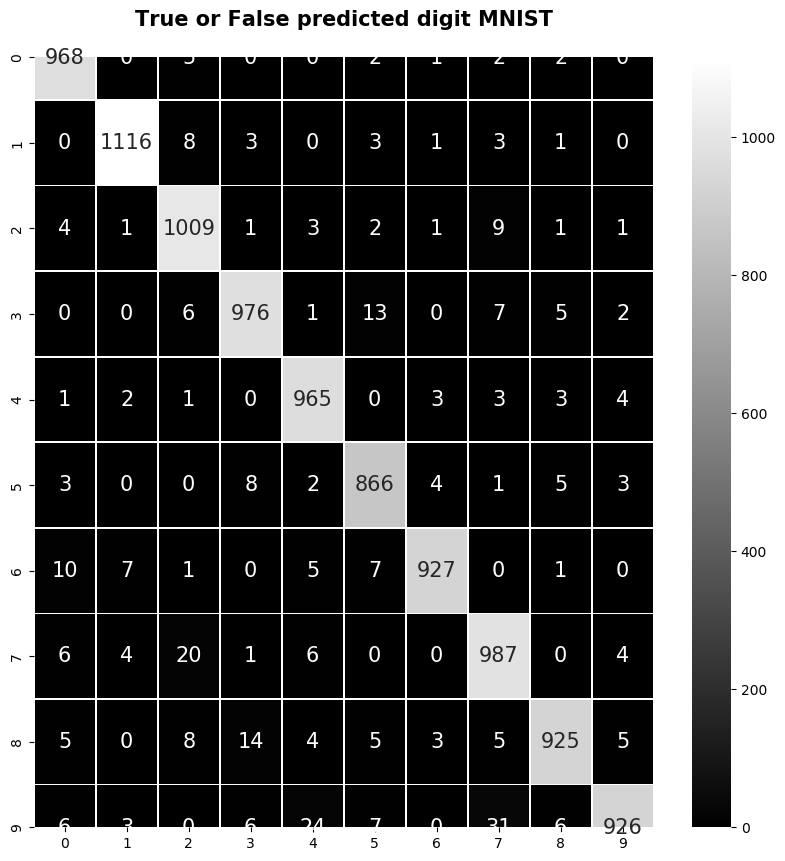

In [28]:
#Confusion matrix for Digit MNIST
con_mat=confusion_matrix(y_test_digit_eval,y_predicts)
plt.style.use('seaborn-deep')
plt.figure(figsize=(10,10))
sns.heatmap(con_mat,annot=True,annot_kws={'size': 15},linewidths=0.5,fmt="d",cmap="gray")
plt.title('True or False predicted digit MNIST\n',fontweight='bold',fontsize=15)
plt.show()

In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_test_digit_eval,y_predicts))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.98      0.98      0.98      1135
           2       0.95      0.98      0.97      1032
           3       0.97      0.97      0.97      1010
           4       0.96      0.98      0.97       982
           5       0.96      0.97      0.96       892
           6       0.99      0.97      0.98       958
           7       0.94      0.96      0.95      1028
           8       0.97      0.95      0.96       974
           9       0.98      0.92      0.95      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



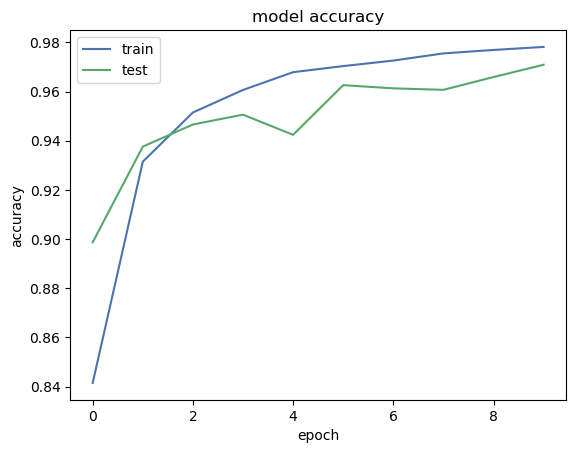

In [30]:
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()


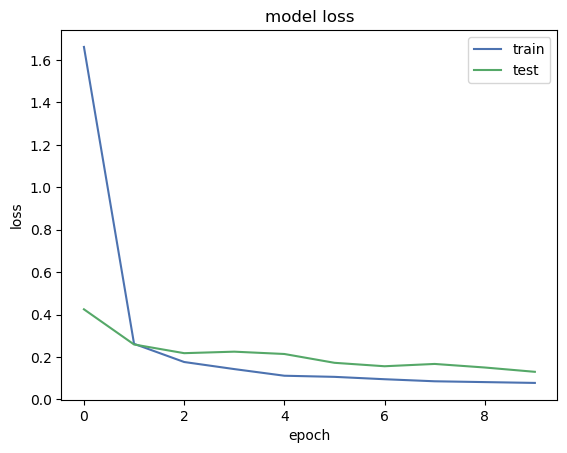

In [31]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')

plt.legend(['train','test'],loc='best')

plt.show()

In [32]:
#Predict one image
y_predict_single = model.predict(
    X_test_digit[[3]]
)

y_predicts_single = np.argmax(
    y_predict_single,
    axis=1
)

y_test_digit_eval = np.argmax(
    y_test_digit,
    axis=1
)

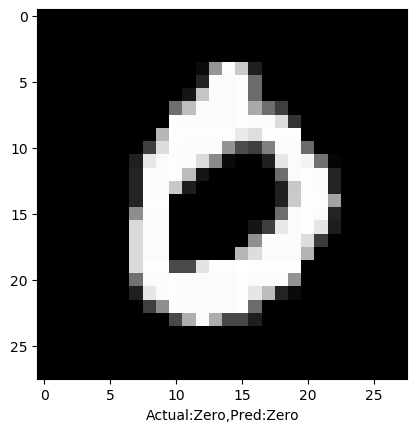

In [33]:
col_names = [
    'Zero','One','Two','Three','Four',
    'Five','Six','Seven','Eight','Nine'
]

plt.imshow(
    X_test_digit[3].reshape(28,28),
    cmap='gray'
)

plt.xlabel(
    "Actual:{},Pred:{}".format(
        col_names[np.argmax(y_test_digit[3])],
        col_names[y_predicts_single[0]]
    )
)

plt.show()